IMPORTACIÓN DE LIBRERIAS NECESARIAS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error



CREAMOS VARIABLES ALEATORIAS CON NUMPY

In [7]:
rng = np.random.default_rng(42)

dias = np.arange(1, 61)

ventas = 100 + dias * 2.5 + rng.normal(0, 10, 60)

df = pd.DataFrame({
    "dia": dias,
    "ventas": ventas
})

df.head()

,dia,ventas
0,1,105.547171
1,2,94.600159
2,3,115.004512
3,4,119.405647
4,5,92.989648


SEPARAMOS EN ENTRENAMIENTO Y TESTEO. ENTRENAMOS CON LOS DATOS DE LOS PRIMEROS 45 Y EVALUAMOS EL MODELO CON LOS ÚLTIMOS 15

In [8]:
X_train = df[["dia"]][:45]
y_train = df["ventas"][:45]

X_test = df[["dia"]][45:]
y_test = df["ventas"][45:]

AHORA VAMOS A UTILIZAR LinearRegression de Scikit-learn

In [9]:
modelo = LinearRegression()

modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.57]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['dia']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,98.84
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


OBSERVAMOS LOS RESULTADOS DEL ENTRENAMIENTO

In [10]:
print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

Pendiente: 2.574462223510722
Intercepto: 98.84300129672849


EVALUAMOS AL MODELO LOS ULTIMOS 15 DÍAS

In [11]:
predicciones = modelo.predict(X_test)

CALCULAMOS EL ERROR ABSOLUTO MEDIO (MAE)

In [12]:
mae = mean_absolute_error(y_test, predicciones)

print("Error absoluto medio:", mae)

Error absoluto medio: 6.2019330063947375


VAMOS A COMPARAR LA VENTAS REALES CON LAS QUE PREDIJO EL MODELO 

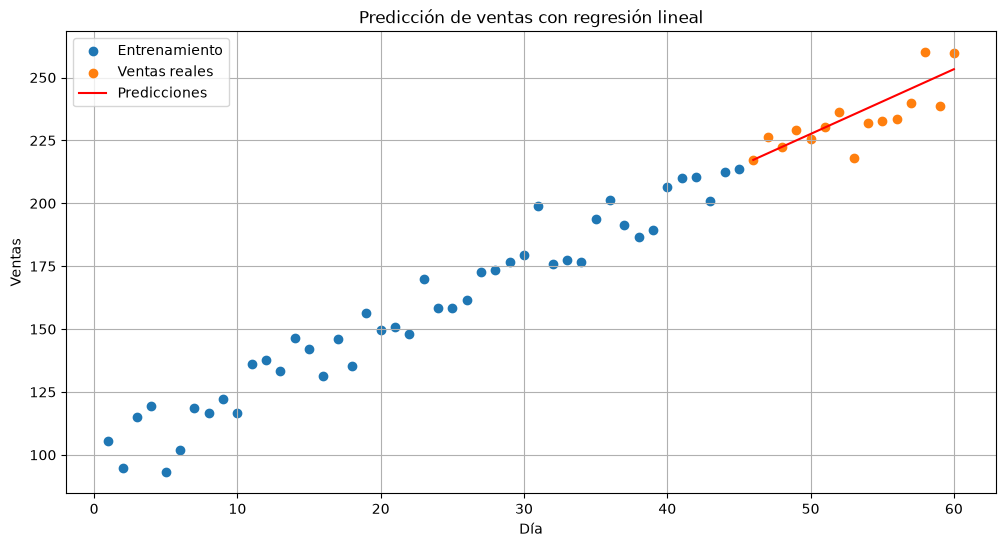

In [13]:
plt.figure(figsize=(12, 6))

plt.scatter(X_train, y_train, label="Entrenamiento")
plt.scatter(X_test, y_test, label="Ventas reales")
plt.plot(X_test, predicciones, color="red", label="Predicciones")

plt.xlabel("Día")
plt.ylabel("Ventas")
plt.title("Predicción de ventas con regresión lineal")

plt.legend()
plt.grid()
plt.show()

HOLA